## Evaluation of internal thermal resistance in a single U-tube borehole using the multipole method
The case is that of Claesson and Hellström (2011) [DOI: 10.1080/10789669.2011.609927].
The expected results are:
| $J$ | $K_{1b}$ | $K_{12}$ | $K_{2b}$ |
| --- | --- | --- | --- |
| 0 | 3.698 | 0.240 | 3.742 |
| 1 | 3.683 | 0.243 | 3.727 |
| 2 | 3.681 | 0.242 | 3.724 |
| 3 | 3.680 | 0.242 | 3.724 |

Note : $K_{ij}$ is the inverse of the delta-circuit thermal resistance $R^\Delta_{ij}$.

In [1]:
from jax import numpy as jnp
from matplotlib import pyplot as plt
import numpy as np
import pandas as pd

import pygfunction3 as gt3

### Parameters of the borehole

In [2]:
# Borehole dimensions
r_b = 0.070         # Borehole radius (m)

# Pipe dimensions
n_p = 2             # Number of pipes
# Pipe outer radius (m)
r_p = 0.02 * np.ones(n_p)

# Pipe positions
# Single U-tube [(x_1, y_1), (x_2, y_2)]
p = [(0.03, 0.00), (-0.03, 0.02)]

# Ground properties
k_s = 2.5           # Ground thermal conductivity (W/m.K)

# Grout properties
k_b = 1.5           # Grout thermal conductivity (W/m.K)

# Fluid properties
# Fluid to outer pipe wall thermal resistance (m.K/W)
R_fp = 1.2 / (2 * np.pi * k_b) * np.ones(n_p) * np.array([1., 1.])

### Plot Borehole geometry

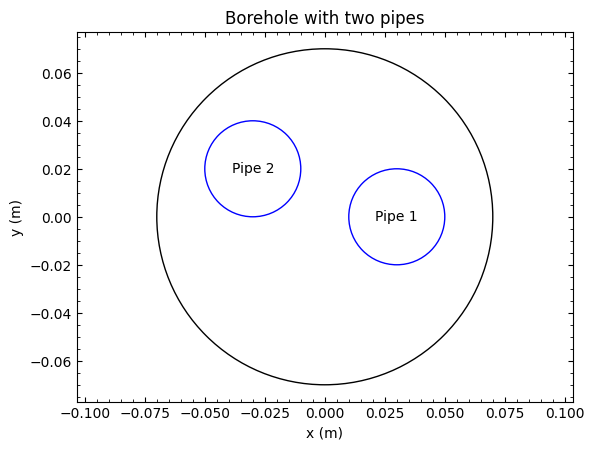

In [3]:
fig, ax = plt.subplots()
gt3.plot._format_axis(ax, axis_labels=['x (m)', 'y (m)'], equal=True)
# Pipes
for i, (_r, _p) in enumerate(zip(r_p, p)):
    # Draw the boundary
    ax.add_patch(plt.Circle(_p, _r, color='blue', fill=False))
    # Label the pipe
    ax.text(_p[0], _p[1], f'Pipe {i+1}', ha='center', va='center')
# Borehole
ax.add_patch(plt.Circle((0., 0.), r_b, color='black', fill=False))

ax.relim()
ax.autoscale_view()
ax.set_title('Borehole with two pipes')
plt.show()

### Evaluate thermal resistances
Evaluate each multipole order

In [4]:
J_max = 3         # Maximum multipole order
R_delta = np.zeros((J_max, n_p, n_p))
for J in range(1, J_max+1):
    multipole = gt3.Multipole(r_b, r_p, p, J=J)
    R_delta[J-1] = multipole.thermal_resistances(k_s, k_b, R_fp)
K_delta = 1 / R_delta

In [5]:
# Format and print dataframe
results = np.stack((K_delta[..., 0, 0], K_delta[..., 0, 1], K_delta[..., 1, 1]), axis=-1)
variable = [r'$K_{1b}$', r'$K_{12}$', r'$K_{2b}$']

df = pd.DataFrame(
    results,
    columns=variable,
    index=np.arange(1, J_max + 1))
df.index.name = 'J'
df

,$K_{1b}$,$K_{12}$,$K_{2b}$
J,,,
1,3.683213,0.242535,3.726882
2,3.680609,0.241854,3.724272
3,3.680293,0.241867,3.723952


Time for evaluation of thermal resistances

In [6]:
%%timeit
multipole.thermal_resistances(k_s, k_b, R_fp)

82.2 μs ± 3.76 μs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


### Temperature field

Heat injection rate at each pipe

In [7]:
q = np.array([3.680, 3.724])

Temperature around the borehole wall

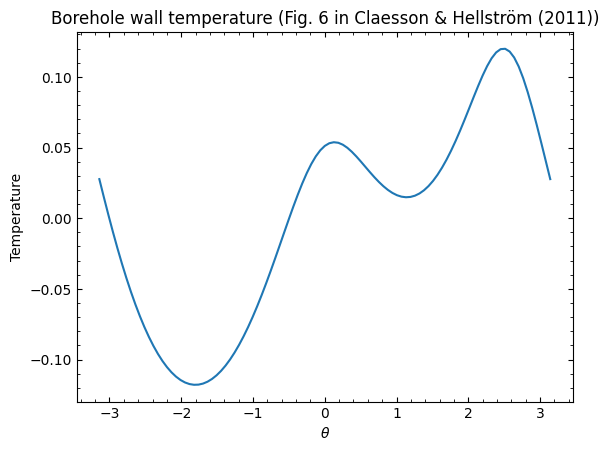

In [8]:
theta_multipole = np.linspace(-np.pi, np.pi, num=101)
T_b_wall_multipole = multipole.borehole_wall_temperatures(theta_multipole, q, 0., k_s, k_b, R_fp)

fig, ax = plt.subplots()
gt3.plot._format_axis(ax, axis_labels=['$\\theta$', 'Temperature'])
ax.plot(theta_multipole, T_b_wall_multipole, '-')
ax.set_title('Borehole wall temperature (Fig. 6 in Claesson & Hellström (2011))')
plt.show()

2D temperature field

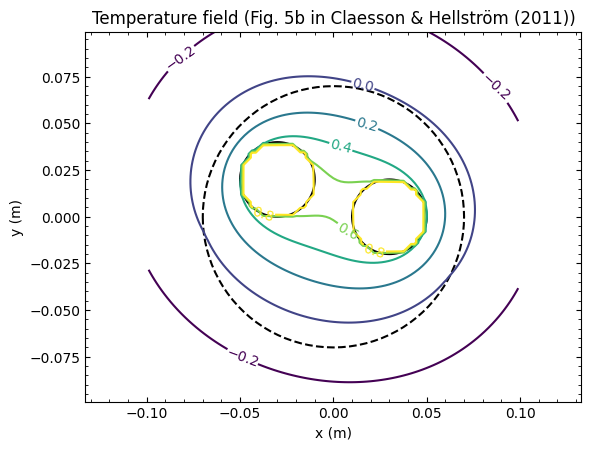

In [9]:
x_min, x_max = -0.1, 0.1
y_min, y_max = -0.1, 0.1
N_x = N_y = 101
x, y = np.meshgrid(np.linspace(x_min, x_max, N_x), np.linspace(y_min, y_max, N_y))
p_T = np.stack((x.flatten(), y.flatten()), axis=-1)
T = multipole.temperatures(p_T, q, 0., k_s, k_b, R_fp)
T = T.reshape((N_y, N_x))

fig, ax = plt.subplots();
gt3.plot._format_axis(ax, axis_labels=['x (m)', 'y (m)'], equal=True);
ax.plot(r_b * np.cos(theta_multipole), r_b * np.sin(theta_multipole), 'k--');
for i, (_r, _p) in enumerate(zip(r_p, p)):
    ax.plot(_p[0] + _r * np.cos(theta_multipole), _p[1] + _r * np.sin(theta_multipole), 'k-')
CS = ax.contour(T, extent=(x_min, x_max, y_min, y_max), levels=np.linspace(-0.2, 0.8, 6), origin='lower');
ax.clabel(CS, fontsize=10)
ax.set_title('Temperature field (Fig. 5b in Claesson & Hellström (2011))');